# Construção de Modelo de EAD (Exposure at Default)

## Objetivo
Construir um modelo de Machine Learning utilizando `HistGradientBoostingRegressor` para prever o **CCF (*Credit Conversion Factor*)** e estimar o **EAD (*Exposure at Default*)** em uma carteira de crédito rotativo, validando os resultados em uma safra futura (*Out-of-Time*).

---

In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Dados.csv', sep = ',', header = 0)
df.head()

,Unnamed: 0,safra_default,renda_mensal,limite_12m,saldo_12m,variacao_saldo_3m,qtd_atrasos_curtos_6m,pagou_minimo_ult_fatura,saldo_default
0,0,2023,1730.33,3741.20,3489.72,0.5783,3,0,3609.51
1,1,2025,2074.36,3791.04,304.71,0.3440,0,0,524.29
2,2,2024,4422.27,9891.87,4916.79,0.3238,2,1,8583.27
3,3,2024,2024.47,4361.83,1213.13,0.1378,0,0,1510.13
4,4,2022,6350.68,19650.77,9963.94,0.2848,1,0,13872.85


### Passo 1: Conhecendo os dados
- Verificação do comportamento dos dados envolvendo:
  - `safra_default`
  - `renda_mensal`
  - `limite_12m` e `saldo_12m` (foto de 12 meses antes do calote)
  - `variacao_saldo_3m`, `qtd_atrasos_curtos_6m` e `pagou_minimo_ult_fatura` (comportamento)
  - `saldo_default` (quanto o cliente realmente devia no dia do calote)

In [3]:
df_copy = df.copy()

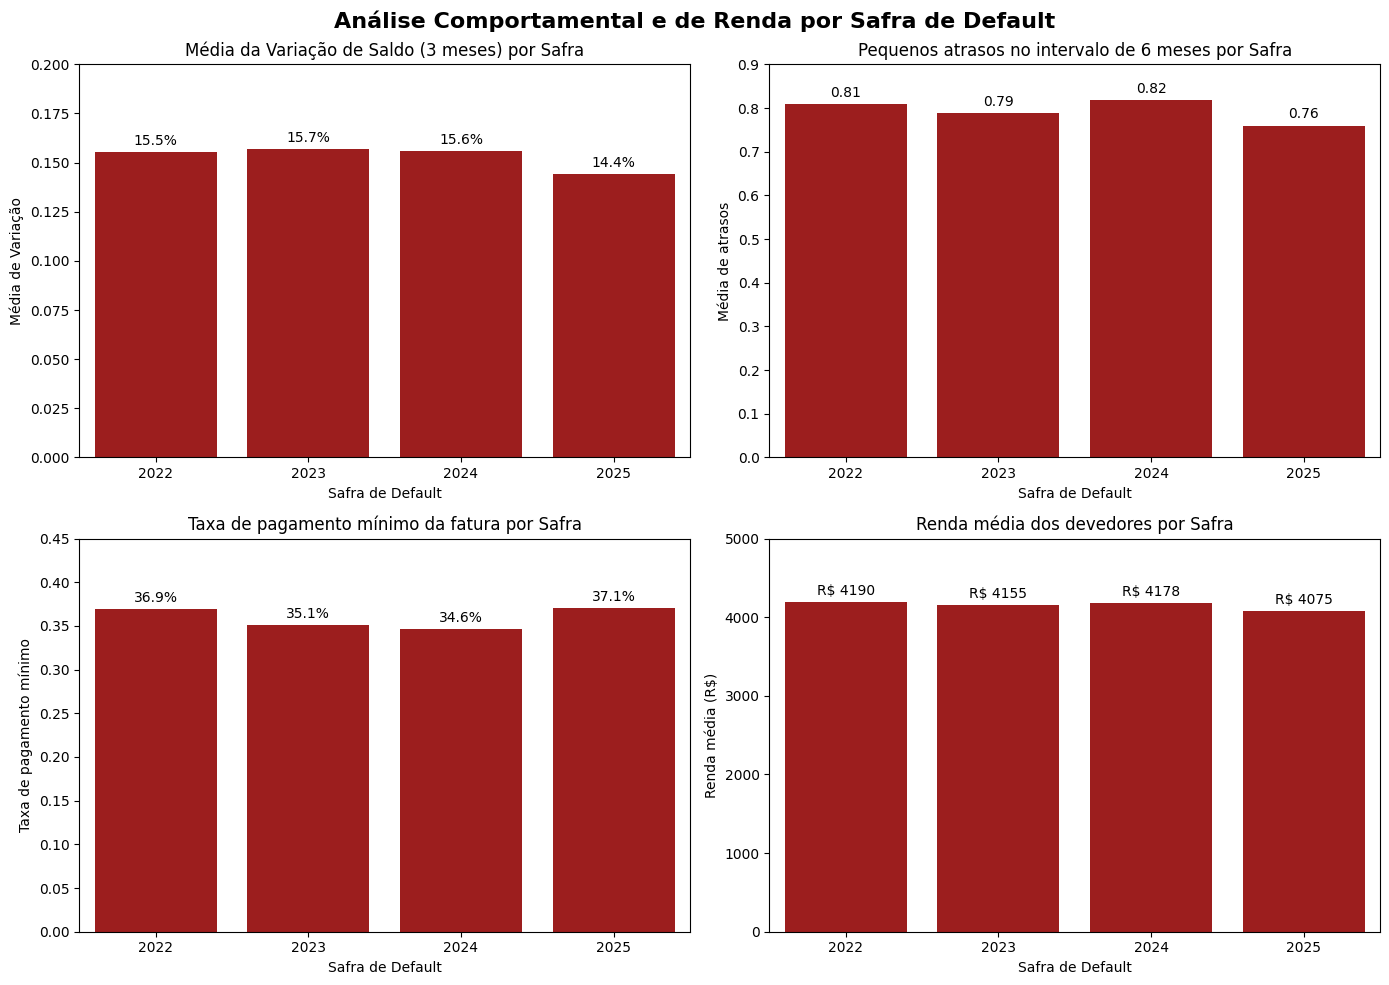

In [4]:
variacao_3m = df_copy.groupby('safra_default')['variacao_saldo_3m'].mean().reset_index(name='media')
atrasos = df_copy.groupby('safra_default')['qtd_atrasos_curtos_6m'].mean().reset_index(name='media')
pagamento_minimo = df_copy.groupby('safra_default')['pagou_minimo_ult_fatura'].mean().reset_index(name='media')
renda_media = df_copy.groupby('safra_default')['renda_mensal'].mean().reset_index(name='media')


fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Análise Comportamental e de Renda por Safra de Default', fontsize=16, fontweight='bold')

cor = "#B10909"


sns.barplot(data=variacao_3m, x='safra_default', y='media', color=cor, ax=axes[0, 0])
axes[0, 0].set_title('Média da Variação de Saldo (3 meses) por Safra', fontsize=12)
axes[0, 0].set_ylabel('Média de Variação')
axes[0, 0].set_xlabel('Safra de Default')
axes[0, 0].bar_label(axes[0, 0].containers[0], fmt=lambda x: f'{x:.1%}', padding=3)
axes[0, 0].set_ylim(0, 0.20) 

sns.barplot(data=atrasos, x='safra_default', y='media', color=cor, ax=axes[0, 1])
axes[0, 1].set_title('Pequenos atrasos no intervalo de 6 meses por Safra', fontsize=12)
axes[0, 1].set_ylabel('Média de atrasos')
axes[0, 1].set_xlabel('Safra de Default')
axes[0, 1].bar_label(axes[0, 1].containers[0], fmt='%.2f', padding=3)
axes[0, 1].set_ylim(0, 0.90) 


sns.barplot(data=pagamento_minimo, x='safra_default', y='media', color=cor, ax=axes[1, 0])
axes[1, 0].set_title('Taxa de pagamento mínimo da fatura por Safra', fontsize=12)
axes[1, 0].set_ylabel('Taxa de pagamento mínimo')
axes[1, 0].set_xlabel('Safra de Default')
axes[1, 0].bar_label(axes[1, 0].containers[0], fmt=lambda x: f'{x:.1%}', padding=3)
axes[1, 0].set_ylim(0, 0.45)  # Dá uma folga no topo para o texto não encostar na borda


sns.barplot(data=renda_media, x='safra_default', y='media', color=cor, ax=axes[1, 1])
axes[1, 1].set_title('Renda média dos devedores por Safra', fontsize=12)
axes[1, 1].set_ylabel('Renda média (R$)')
axes[1, 1].set_xlabel('Safra de Default')
axes[1, 1].bar_label(axes[1, 1].containers[0], fmt='R$ %.0f', padding=3)
axes[1, 1].set_ylim(0, 5000)


plt.tight_layout()
plt.show()

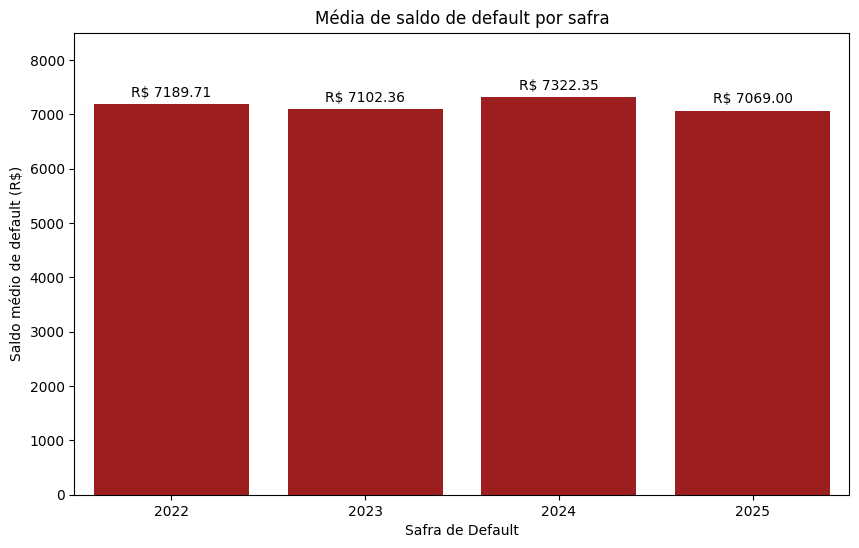

In [5]:
saldo = df_copy.groupby('safra_default')['saldo_default'].mean().reset_index(name='media')

plt.figure(figsize=(10, 6))
sns.barplot(data=saldo, x='safra_default', y='media', color=cor)
plt.bar_label(plt.gca().containers[0], fmt='R$ %.2f', padding=3)
plt.ylim(0, 8500)
plt.xlabel('Safra de Default')
plt.ylabel('Saldo médio de default (R$)')
plt.title('Média de saldo de default por safra')
plt.show()

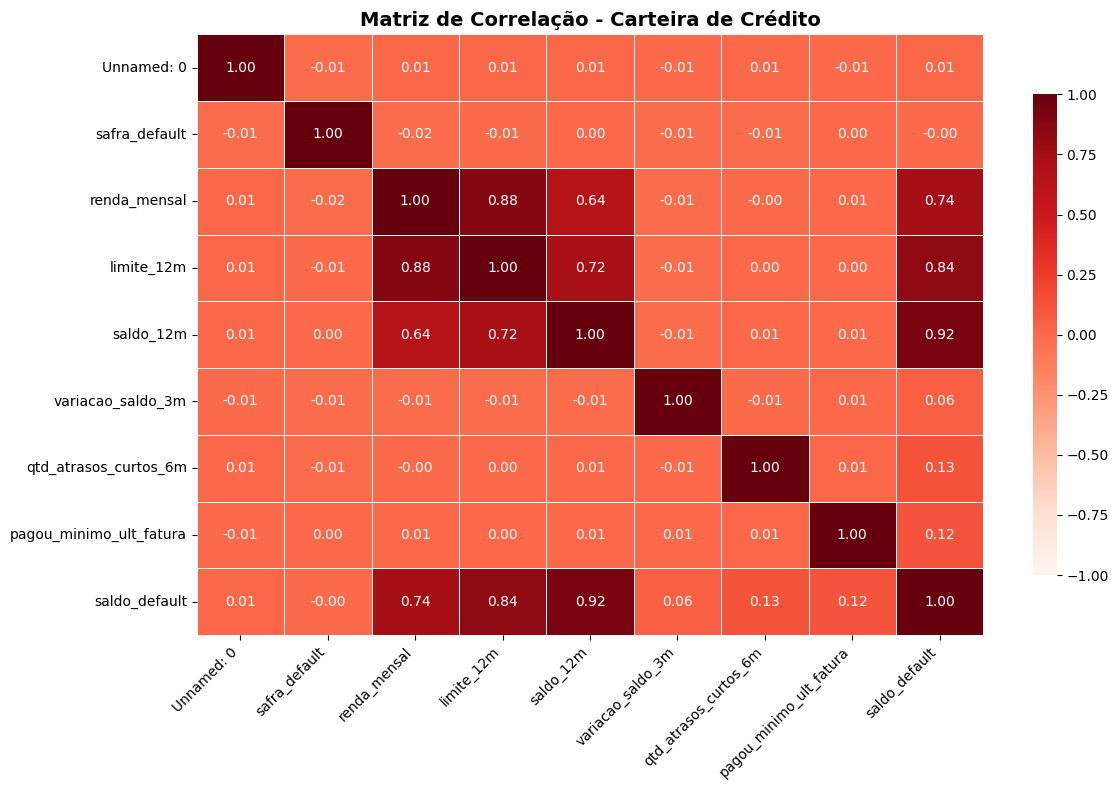

In [6]:
corr = df_copy.corr(numeric_only = True)

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot = True,           
    fmt = ".2f",            
    cmap= "Reds",          
    vmin=-1, vmax=1,      
    linewidths = 0.5,       
    cbar_kws={"shrink": 0.8}
)

plt.title("Matriz de Correlação - Carteira de Crédito", fontsize=14, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Passo 2: Filtragem a base e criar a variável alvo (`ccf_realizado`)
- **Filtro de elegibilidade:** Manter apenas os clientes que possuíam algum limite livre 12 meses antes do calote (`limite_12m > saldo_12m`), evitando divisão por zero na fórmula do CCF.
- **Limite livre:** Criar a coluna `limite_livre_12m` subtraindo `saldo_12m` de `limite_12m`.
- **Target (CCF):** Calcular a razão `(saldo_default - saldo_12m) / limite_livre_12m`.
- **Tratamento de extremos (*Clipping*):** Para garantir que o `ccf_realizado` fique estritamente entre `0` e `1`.

Como  a fórmula a ser seguida é:

* **Cálculo do Alvo Histórico (CCF Realizado):**
  $$\text{CCF}_{\text{realizado}} = \frac{\text{Saldo no Default} - \text{Saldo 12m Antes}}{\text{Limite 12m Antes} - \text{Saldo 12m Antes}}$$

Vamos selecionar apenas os clientes que possuam um limite nos últimos 12 meses maior que o saldo devedor no mesmo período, assim evitando uma divisão por zero e colapsando fórmula.

In [7]:
df_copy.query('limite_12m > saldo_12m', inplace= True)

df_copy['limite_livre_12m'] = df_copy['limite_12m'] - df_copy['saldo_12m']

#ccf_bruto = (df_copy["saldo_default"] - df_copy["saldo_12m"]) / df_copy["limite_livre_12m"]

df_copy['ccf_bruto'] = (df_copy['saldo_default'] - df_copy['saldo_12m']) / df_copy['limite_livre_12m']

df_copy

,Unnamed: 0,safra_default,renda_mensal,limite_12m,saldo_12m,variacao_saldo_3m,qtd_atrasos_curtos_6m,pagou_minimo_ult_fatura,saldo_default,limite_livre_12m,ccf_bruto
0,0,2023,1730.33,3741.20,3489.72,0.5783,3,0,3609.51,251.48,0.476340
1,1,2025,2074.36,3791.04,304.71,0.3440,0,0,524.29,3486.33,0.062983
2,2,2024,4422.27,9891.87,4916.79,0.3238,2,1,8583.27,4975.08,0.736969
3,3,2024,2024.47,4361.83,1213.13,0.1378,0,0,1510.13,3148.70,0.094325
4,4,2022,6350.68,19650.77,9963.94,0.2848,1,0,13872.85,9686.83,0.403528
...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,2025,3590.11,10349.24,5435.91,0.0095,0,1,6761.45,4913.33,0.269784
9996,9996,2025,5411.05,14172.11,11824.81,0.2350,1,0,12927.69,2347.30,0.469850
9997,9997,2025,5986.48,23466.21,11560.64,-0.0255,0,0,11565.32,11905.57,0.000393
9998,9998,2023,2569.16,6834.81,2471.29,0.1696,2,1,4537.36,4363.52,0.473487


Vamos utilizar  `np.clip(..., 0.0, 1.0)` para tartar os extremos e manter tudo entre 0.0 e 1.0 como desejado

In [8]:
df_copy['ccf_realizado'] = np.clip(df_copy['ccf_bruto'], 0, 1)
df_copy

,Unnamed: 0,safra_default,renda_mensal,limite_12m,saldo_12m,variacao_saldo_3m,qtd_atrasos_curtos_6m,pagou_minimo_ult_fatura,saldo_default,limite_livre_12m,ccf_bruto,ccf_realizado
0,0,2023,1730.33,3741.20,3489.72,0.5783,3,0,3609.51,251.48,0.476340,0.476340
1,1,2025,2074.36,3791.04,304.71,0.3440,0,0,524.29,3486.33,0.062983,0.062983
2,2,2024,4422.27,9891.87,4916.79,0.3238,2,1,8583.27,4975.08,0.736969,0.736969
3,3,2024,2024.47,4361.83,1213.13,0.1378,0,0,1510.13,3148.70,0.094325,0.094325
4,4,2022,6350.68,19650.77,9963.94,0.2848,1,0,13872.85,9686.83,0.403528,0.403528
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,2025,3590.11,10349.24,5435.91,0.0095,0,1,6761.45,4913.33,0.269784,0.269784
9996,9996,2025,5411.05,14172.11,11824.81,0.2350,1,0,12927.69,2347.30,0.469850,0.469850
9997,9997,2025,5986.48,23466.21,11560.64,-0.0255,0,0,11565.32,11905.57,0.000393,0.000393
9998,9998,2023,2569.16,6834.81,2471.29,0.1696,2,1,4537.36,4363.52,0.473487,0.473487


### Passo 3: Engenharia de Atributos (*Feature Engineering*)
- Vamos criar duas novas razões financeiras usando **apenas dados observados 12 meses antes do default**:
  - `taxa_utilizacao_12m`: razão entre `saldo_12m` e `limite_12m`.
  - `comprometimento_renda`: razão entre `saldo_12m` e `renda_mensal`.
- Será definida uma lista `features` contendo apenas as variáveis explicativas válidas:
  - `limite_12m`, `saldo_12m`, `limite_livre_12m`, `taxa_utilizacao_12m`, `comprometimento_renda`, `variacao_saldo_3m`, `qtd_atrasos_curtos_6m`, `pagou_minimo_ult_fatura`.

In [9]:
df_copy['taxa_utilizacao_12m'] = df_copy['saldo_12m'] / df_copy['limite_12m']

df_copy['comprometimento_renda'] = df_copy['saldo_12m'] / df_copy['renda_mensal']

In [10]:
df_copy.columns

Index(['Unnamed: 0', 'safra_default', 'renda_mensal', 'limite_12m',
       'saldo_12m', 'variacao_saldo_3m', 'qtd_atrasos_curtos_6m',
       'pagou_minimo_ult_fatura', 'saldo_default', 'limite_livre_12m',
       'ccf_bruto', 'ccf_realizado', 'taxa_utilizacao_12m',
       'comprometimento_renda'],
      dtype='object')

In [11]:
features = ['limite_12m', 'saldo_12m', 'qtd_atrasos_curtos_6m', 'pagou_minimo_ult_fatura', 'variacao_saldo_3m' , 'taxa_utilizacao_12m', 'comprometimento_renda']

### Passo 4: Divisão Temporal (*Out-of-Time* — OOT)
- Vamos separar o dataset por safra, sem embaralhar os anos:
  - **Base de Treino (`treino`):** registros onde `safra_default == 2022`, `safra_default == 2023` e `safra_default == 2024`.
  - **Base de Teste (`teste_oot`):** registros onde `safra_default == 2025`.

In [12]:
treino = df_copy[df_copy['safra_default'].isin([2022, 2023, 2024]) ].copy()

alvo = treino['ccf_realizado']

teste = df_copy[df_copy['safra_default'] == 2025].copy()


### Passo 5: Treinar o Modelo de Machine Learning
- Instanciar o `HistGradientBoostingRegressor` definindo hiperparâmetros conservadores para evitar *overfitting* (ex.: `max_depth=4`, `learning_rate=0.05`, `max_iter=200`, `random_state=42`).
- Treinar o modelo (`.fit()`) passando `treino[features]` como entrada (`X`) e `treino["ccf_realizado"]` como alvo (`y`).

In [ ]:
modelo_ccf = HistGradientBoostingRegressor(
    max_depth = 4,
    learning_rate = 0.05,
    max_iter = 200,
    random_state = 42 
)



modelo_ccf.fit(treino[features], alvo)

,loss,'squared_error'
,quantile,None
,learning_rate,0.05
,max_iter,200
,max_leaf_nodes,31
,max_depth,4
,min_samples_leaf,20
,l2_regularization,0.0
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'


### Passo 6: Prever o CCF e Calcular o EAD na Base de Teste
- Gerar previsões do CCF na base `teste` usando `.predict([features])` e aplicar `np.clip(..., 0.0, 1.0)` para salvar na coluna `ccf_previsto`.
- Converter o percentual previsto em valor financeiro (`ead_previsto`) aplicando a equação geral do EAD na base `teste`.


* **Equação Geral do EAD (Previsão em R$):**
  $$\text{EAD} = \text{Saldo Atual} + \text{CCF}_{\text{previsto}} \times (\text{Limite Total} - \text{Saldo Atual})$$

In [ ]:
previsoes = modelo_ccf.predict(teste[features])
teste['ccf_previsto'] = np.clip(previsoes, 0.0, 1.0)


teste["ead_previsto"] = (teste["saldo_12m"] + teste["ccf_previsto"] * teste["limite_livre_12m"] ).round(2)


### Passo 7: Avaliar o Desempenho do Modelo
- **Erro do CCF:** Calcular o `mean_absolute_error` entre `ccf_realizado` e `ccf_previsto`.
- **Erro Financeiro do EAD:** Calcular o `mean_absolute_error` (MAE) e o `root_mean_squared_error` (RMSE) comparando `saldo_default` (real) com `ead_previsto`.
- **Calibração da Carteira:** Comparar a média de `saldo_default` com a média de `ead_previsto` na safra 2025 para verificar se o modelo está bem calibrado no agregado.

In [15]:
mae_ccf = mean_absolute_error(teste["ccf_realizado"], teste["ccf_previsto"])
r2_ccf = r2_score(teste["ccf_realizado"], teste["ccf_previsto"])
mae_ead = mean_absolute_error(teste["saldo_default"], teste["ead_previsto"])
rmse_ead = root_mean_squared_error(teste["saldo_default"], teste["ead_previsto"])
r2_ead = r2_score(teste["saldo_default"], teste["ead_previsto"])

print(f"Base filtrada (com limite livre > 0): {len(df_copy)} de {len(df)} clientes")
print(f"Erro Médio Absoluto (MAE) do CCF: {mae_ccf:.4f} (cerca de {mae_ccf:.1%} de erro médio)")
print(f"Erro Médio Absoluto (MAE) do EAD: R$ {mae_ead:,.2f}")
print(f"Raiz do Erro Quadrático (RMSE) do EAD: R$ {rmse_ead:,.2f}")

print(f'O score R² do modelo de EAD treinado com os dados é: {round(r2_ead,3)}')

Base filtrada (com limite livre > 0): 9917 de 10000 clientes
Erro Médio Absoluto (MAE) do CCF: 0.0976 (cerca de 9.8% de erro médio)
Erro Médio Absoluto (MAE) do EAD: R$ 576.45
Raiz do Erro Quadrático (RMSE) do EAD: R$ 917.57
O score R² do modelo de EAD treinado com os dados é: 0.967


In [16]:
print(f"CALIBRAÇÃO (Média Real vs. Prevista na safra 2025):")
print(f"EAD Médio Real: R$ {teste['saldo_default'].mean():,.2f} | EAD Médio Previsto: R$ {teste['ead_previsto'].mean():,.2f}")


CALIBRAÇÃO (Média Real vs. Prevista na safra 2025):
EAD Médio Real: R$ 7,010.14 | EAD Médio Previsto: R$ 7,013.64


In [17]:
print("\nExemplo de 5 clientes da safra de teste (2025):")
colunas_exibir = ["limite_12m", "saldo_12m", "ccf_realizado", "ccf_previsto", "saldo_default", "ead_previsto"]
print(teste[colunas_exibir].head(5).to_string(index=False))


Exemplo de 5 clientes da safra de teste (2025):
 limite_12m  saldo_12m  ccf_realizado  ccf_previsto  saldo_default  ead_previsto
    3791.04     304.71       0.062983      0.135517         524.29        777.17
   12090.57    2686.25       0.667207      0.589432        8960.88       8229.46
   11164.58    1567.73       0.349627      0.312158        4923.05       4563.46
   11839.99    8341.22       0.271741      0.353450        9291.98       9577.86
   10947.51   10413.35       0.630186      0.636060       10749.97      10753.11


### Regra de Produção para Toda a Carteira
- Vamos criar uma função `prever_ead_carteira_completa(df_carteira, modelo)` que receba qualquer cliente (inclusive aqueles filtrados na segunda etapa por já estarem com 100% do limite utilizado) e aplique:
  - Se `limite_livre_12m > 0`: calcula o EAD usando o CCF previsto pelo modelo.
  - Caso contrário (`limite_livre_12m <= 0`): define o EAD como sendo o próprio `saldo_12m`.

In [18]:
def prever_ead_carteira_completa(df_carteira, modelo_ccf):
    """
    Aplica a regra completa em produção:
    - Se o cliente tem limite livre > 0: usa a fórmula com o CCF do modelo.
    - Se o cliente já estorou 100% do limite: o EAD é o próprio saldo atual.
    """

    dados = df_carteira.copy()
    dados['limite_livre_12m'] = dados['limite_12m'] - dados['saldo_12m']
    dados['taxa_utilizacao_12m'] = dados['saldo_12m'] / dados['limite_12m']
    dados['comprometimento_renda'] = dados['saldo_12m'] / dados['renda_mensal']

    ccf_estimado = np.clip(modelo_ccf.predict(dados[features]), 0.0, 1.0)

    ead_final = np.where(
        dados['limite_livre_12m'] > 0,
        dados['saldo_12m'] + ccf_estimado * (dados['limite_livre_12m']),
        dados['saldo_12m']
    )

    return pd.Series(ead_final, index = df_carteira.index).round(2)

Carteira fictícia com cenários para teste rápido

In [19]:
novos_clientes = pd.DataFrame({
    'renda_mensal': [6000.0, 3500.0, 2800.0, 4500.0, 8000.0],
    'limite_12m': [12000.0, 7000.0, 5000.0, 9000.0, 15000.0],
    'saldo_12m': [1500.0, 3500.0, 4200.0, 9000.0, 0.0],
    'variacao_saldo_3m': [-0.10, 0.20, 0.55, 0.05, 0.00],
    'qtd_atrasos_curtos_6m': [0, 1, 3, 2, 0],
    'pagou_minimo_ult_fatura': [0, 0, 1, 1, 0]
})

novos_clientes['ead_previsto'] = prever_ead_carteira_completa(novos_clientes, modelo_ccf)
novos_clientes

,renda_mensal,limite_12m,saldo_12m,variacao_saldo_3m,qtd_atrasos_curtos_6m,pagou_minimo_ult_fatura,ead_previsto
0,6000.0,12000.0,1500.0,-0.10,0,0,1954.05
1,3500.0,7000.0,3500.0,0.20,1,0,4515.80
2,2800.0,5000.0,4200.0,0.55,3,1,4916.04
3,4500.0,9000.0,9000.0,0.05,2,1,9000.00
4,8000.0,15000.0,0.0,0.00,0,0,635.43
